# Clasificación de Animales (UCI Zoo) — Árboles, Random Forest y XGBoost
**Autor:** Ruben Zurita Calzada

Limpieza y renombrado de columnas, análisis exploratorio y comparación de Árbol de Decisión, Random Forest y XGBoost, incluyendo importancia de atributos.
Coloca `zoo.data` dentro de la carpeta `data/` antes de ejecutar (ver README).


In [ ]:
import pandas as pd #Dataframe
import matplotlib.pyplot as plt #Graficas
from sklearn.tree import DecisionTreeClassifier, plot_tree #Armar y graficar el arbol
from sklearn.model_selection import train_test_split #partir los datos (80 - 20)
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score # Metricas
from sklearn.ensemble import RandomForestClassifier #Random Forest
from xgboost import XGBClassifier #XGBoost
from sklearn.preprocessing import LabelEncoder #Función para convertir las clases en numéricas para el XGBoost
import seaborn as sns #Para la matriz

# Importando el archivo a un dataframe de python

In [ ]:
df = pd.read_csv("data/zoo.data", delimiter=",", header=None)
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,wallaby,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1,1
97,wasp,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0,6
98,wolf,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1
99,worm,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,7


# Inspeccionando por valores nulos y tipos de valores
Se puede observar que son valores booleanos exceptuando dos columnas, la columna 13 y la columna 17.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       101 non-null    object
 1   1       101 non-null    int64 
 2   2       101 non-null    int64 
 3   3       101 non-null    int64 
 4   4       101 non-null    int64 
 5   5       101 non-null    int64 
 6   6       101 non-null    int64 
 7   7       101 non-null    int64 
 8   8       101 non-null    int64 
 9   9       101 non-null    int64 
 10  10      101 non-null    int64 
 11  11      101 non-null    int64 
 12  12      101 non-null    int64 
 13  13      101 non-null    int64 
 14  14      101 non-null    int64 
 15  15      101 non-null    int64 
 16  16      101 non-null    int64 
 17  17      101 non-null    int64 
dtypes: int64(17), object(1)
memory usage: 14.3+ KB


In [ ]:
df.describe()

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644,2.831683
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314,2.102709
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,7.000000


#Reordenando, editando y quitando columnas inservibles

In [ ]:
df.drop(columns=[0], inplace=True)
Categorias = df.pop(17)
df.insert(0, 'Categorias', Categorias)
df

,Categorias,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,1,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,1,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,4,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,1,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,1,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,1,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1
97,6,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0
98,1,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
99,7,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0


In [ ]:
# Lista de nombres de las características
nombres_columnas = [
    "Categorias",
    "hair",
    "feathers",
    "eggs",
    "milk",
    "airborne",
    "aquatic",
    "predator",
    "toothed",
    "backbone",
    "breathes",
    "venomous",
    "fins",
    "legs",
    "tail",
    "domestic",
    "catsize"
]
df.columns = nombres_columnas[:df.shape[1]]

In [ ]:
# Diccionario de Animales
Animales = {
    1: 'mamíferos',
    2: 'pájaros',
    3: 'reptiles',
    4: 'peces',
    5: 'anfibios',
    6: 'insectos',
    7: 'aracnidos'
}

#Reemplazando con los nombres de las categorias
df['Categorias'] = df['Categorias'].replace(Animales)
df

,Categorias,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,mamíferos,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,mamíferos,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,peces,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,mamíferos,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,mamíferos,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,mamíferos,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1
97,insectos,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0
98,mamíferos,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
99,aracnidos,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0


# Observar el dataset

In [ ]:
distribucion = df['Categorias'].value_counts()


print("Distribución de clases de animales:")
print(distribucion)

Distribución de clases de animales:
Categorias
mamíferos    41
pájaros      20
peces        13
aracnidos    10
insectos      8
reptiles      5
anfibios      4
Name: count, dtype: int64


In [ ]:
#Calcular la frecuencia de características
frecuencia = df.iloc[:, 1:].apply(pd.Series.value_counts)

#Mostrar la frecuencia de características
print("Frecuencia de características:")
print(frecuencia)

Frecuencia de características:
   hair  feathers  eggs  milk  airborne  aquatic  predator  toothed  backbone  \
0  58.0      81.0  42.0  60.0      77.0     65.0      45.0     40.0      18.0   
1  43.0      20.0  59.0  41.0      24.0     36.0      56.0     61.0      83.0   
2   NaN       NaN   NaN   NaN       NaN      NaN       NaN      NaN       NaN   
4   NaN       NaN   NaN   NaN       NaN      NaN       NaN      NaN       NaN   
5   NaN       NaN   NaN   NaN       NaN      NaN       NaN      NaN       NaN   
6   NaN       NaN   NaN   NaN       NaN      NaN       NaN      NaN       NaN   
8   NaN       NaN   NaN   NaN       NaN      NaN       NaN      NaN       NaN   

   breathes  venomous  fins  legs  tail  domestic  catsize  
0      21.0      93.0  84.0  23.0  26.0      88.0     57.0  
1      80.0       8.0  17.0   NaN  75.0      13.0     44.0  
2       NaN       NaN   NaN  27.0   NaN       NaN      NaN  
4       NaN       NaN   NaN  38.0   NaN       NaN      NaN  
5       NaN    

#Graficas

#¿Cual es la distribución?
Se nota que los animales son mayormente mamíferos, cada vez decreciendo en frecuencia hasta llegar a los anfibios que conforman un 4% del dataset

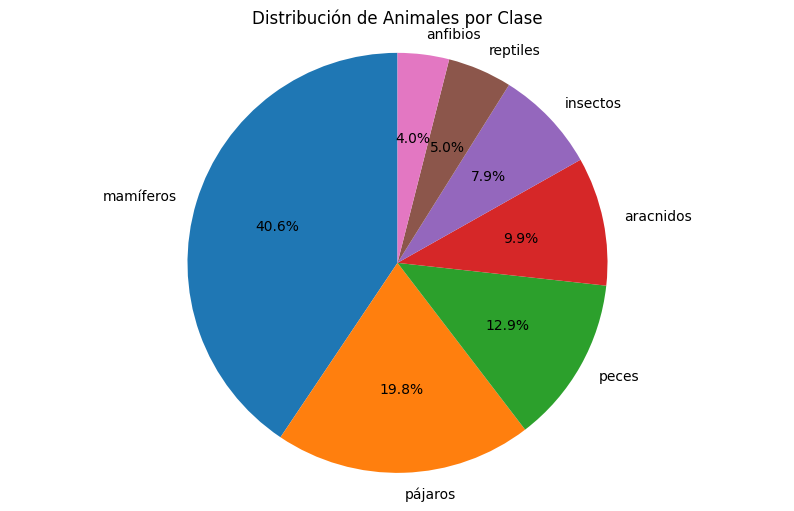

In [ ]:
# Crear el gráfico de pastel
plt.figure(figsize=(10, 6))
plt.pie(distribucion,labels=distribucion.index, autopct='%1.1f%%', startangle=90)

# Configurar el título
plt.title('Distribución de Animales por Clase')

# Mostrar la gráfica
plt.axis('equal')  # Para que el gráfico sea un círculo
plt.show()

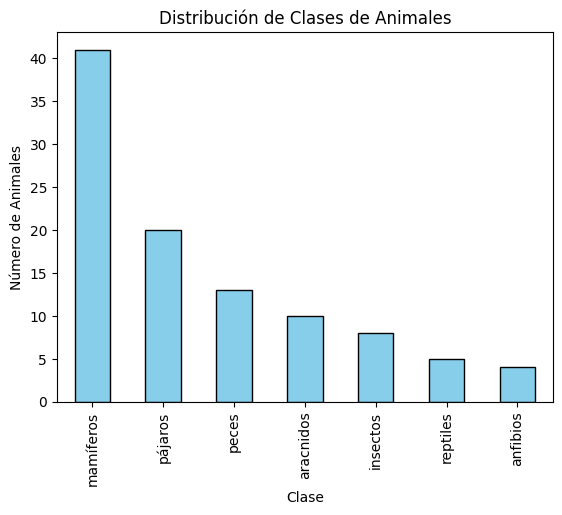

In [ ]:
distribucion.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Distribución de Clases de Animales")
plt.xlabel("Clase")
plt.ylabel("Número de Animales")
plt.show()

In [ ]:
frecuencia.drop(columns=["legs"], inplace=True)
frecuencia.drop(index=frecuencia.index[2:8], inplace=True)

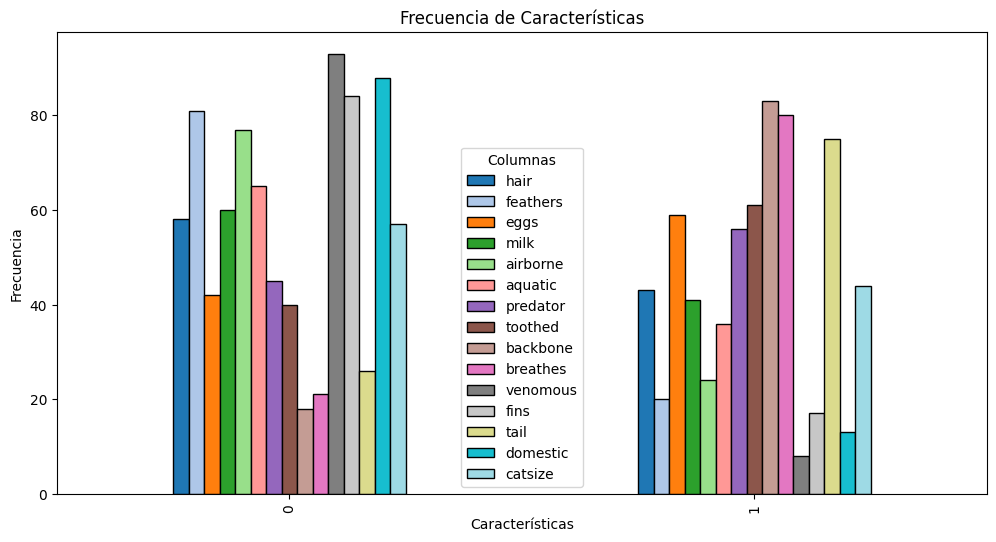

In [ ]:
#Graficar la frecuencia de características
frecuencia.plot(kind='bar', figsize=(12, 6), colormap='tab20', edgecolor='black')
plt.title("Frecuencia de Características")
plt.xlabel("Características")
plt.ylabel("Frecuencia")
plt.legend(title="Columnas")
plt.show()

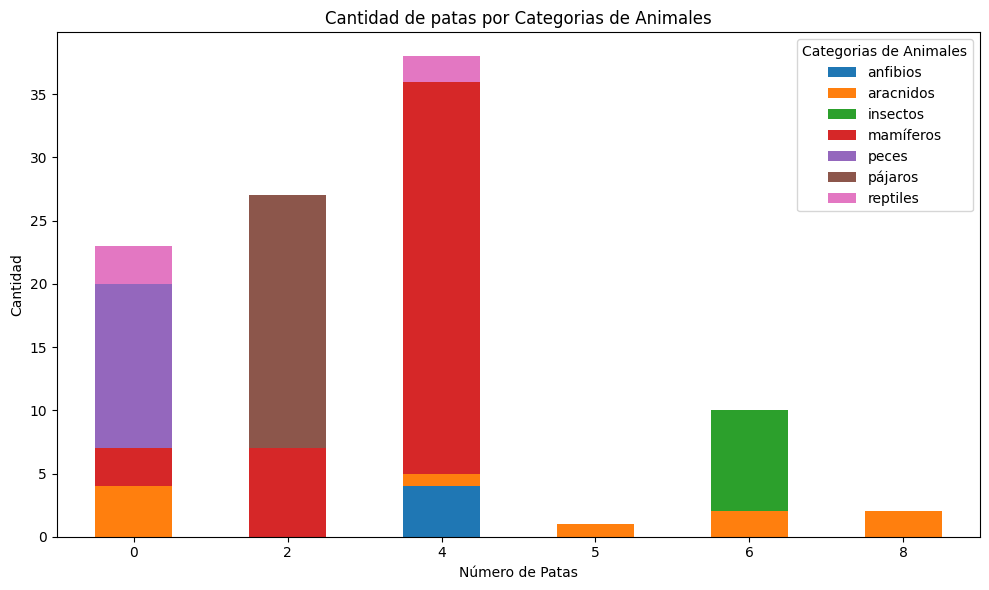

   Categorias  legs  count  total Porcentajes
0    anfibios     4      4      4      100.0%
1   aracnidos     0      4     10       40.0%
2   aracnidos     4      1     10       10.0%
3   aracnidos     5      1     10       10.0%
4   aracnidos     6      2     10       20.0%
5   aracnidos     8      2     10       20.0%
6    insectos     6      8      8      100.0%
7   mamíferos     0      3     41       7.32%
8   mamíferos     2      7     41      17.07%
9   mamíferos     4     31     41      75.61%
10      peces     0     13     13      100.0%
11    pájaros     2     20     20      100.0%
12   reptiles     0      3      5       60.0%
13   reptiles     4      2      5       40.0%


In [ ]:
# Contar el número de ocurrencias de cada combinación de clase y número de patas
count_df = df.groupby(['Categorias', 'legs']).size().reset_index(name='count')

# Crear un gráfico de barras apiladas
count_df.pivot(index='legs', columns='Categorias', values='count').fillna(0).plot(kind='bar', stacked=True, figsize=(10, 6))

# Configurar títulos y etiquetas
plt.title('Cantidad de patas por Categorias de Animales')
plt.xlabel('Número de Patas')
plt.ylabel('Cantidad')
plt.legend(title='Categorias de Animales')
plt.xticks(rotation=0)

# Mostrar la gráfica
plt.tight_layout()
plt.show()

# Calcular el total por clase
total_counts = count_df.groupby('Categorias')['count'].sum().reset_index(name='total')

# Unir el total al DataFrame original
count_df = count_df.merge(total_counts, on='Categorias')
# Calcular el porcentaje
count_df['Porcentajes'] = ((count_df['count'] / count_df['total']) * 100).round(2)
count_df['Porcentajes'] = count_df['Porcentajes'].apply(lambda x: f"{x}%")

print(count_df)

#Crear el arbol

🔍 Precisión del modelo: 92.31%


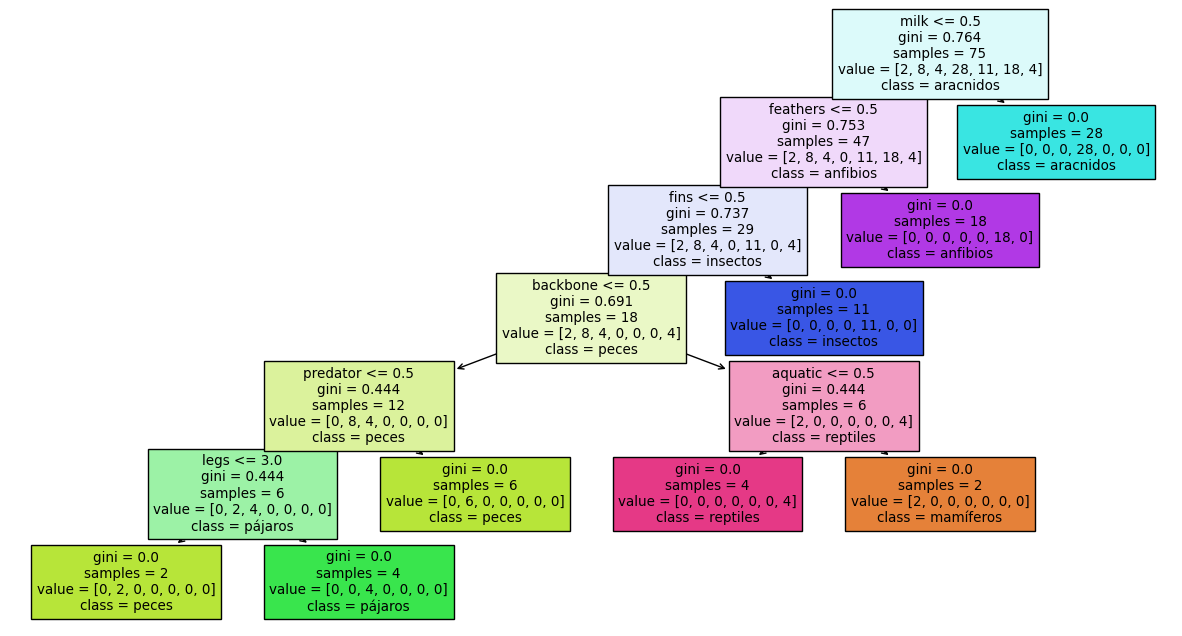

In [ ]:
#Separar características (X) y etiquetas (y)
X = df.iloc[:, 1:]  #Se omiten las etiquetas
y = df.iloc[:, 0]   #las etiquetas

#Dividir en datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

#Crear y entrenar el árbol de decisión
clf = DecisionTreeClassifier(criterion="gini", random_state=42)  #Usando gini
clf.fit(X_train, y_train)

#Predecir y evaluar el modelo
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"🔍 Precisión del modelo: {accuracy:.2%}")

#Visualizar el árbol
plt.figure(figsize=(15, 8))
plot_tree(clf, filled=True, feature_names=X.columns, class_names=y.unique().astype(str))
plt.show()

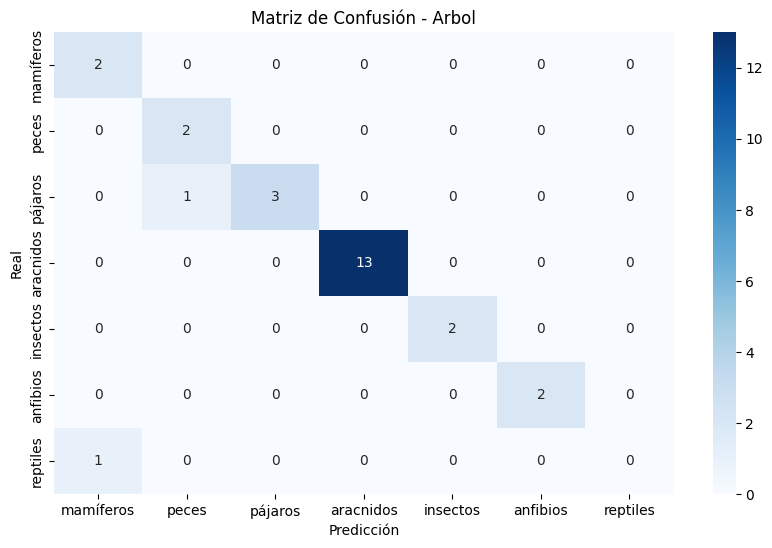

              precision    recall  f1-score   support

    anfibios       0.67      1.00      0.80         2
   aracnidos       0.67      1.00      0.80         2
    insectos       1.00      0.75      0.86         4
   mamíferos       1.00      1.00      1.00        13
       peces       1.00      1.00      1.00         2
     pájaros       1.00      1.00      1.00         2
    reptiles       0.00      0.00      0.00         1

    accuracy                           0.92        26
   macro avg       0.76      0.82      0.78        26
weighted avg       0.91      0.92      0.91        26



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Matriz de confusión
conf_matrix_arbol = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix_arbol, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
plt.title('Matriz de Confusión - Arbol')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()
print(classification_report(y_test, y_pred))


#Random Forest

In [ ]:
# Entrenar el Random Forest
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X_train, y_train)

# Predecir y calcular la precisión del Random Forest
y_pred_forest = random_forest.predict(X_test)
accuracy_forest = accuracy_score(y_test, y_pred_forest)


# Mostrar las precisiones
print(f'Precisión del Árbol de Decisión: {accuracy:.2f}')
print(f'Precisión del Random Forest: {accuracy_forest:.2f}')

Precisión del Árbol de Decisión: 0.92
Precisión del Random Forest: 0.96


#¿Más árboles es mejor?
Mientras más arboles va mejorando gradualmente hasta llegar a 6, después de 6 realmente no hay diferencia entre 6 o 2000.

In [ ]:
# Entrenar el Random Forest con más arboles
random_forest = RandomForestClassifier(n_estimators=6, random_state=42)
random_forest.fit(X_train, y_train)

# Predecir y calcular la precisión del Random Forest
y_pred_forest = random_forest.predict(X_test)
accuracy_forest = accuracy_score(y_test, y_pred_forest)


# Mostrar las precisiones
print(f'Precisión del Árbol de Decisión: {accuracy:.2f}')
print(f'Precisión del Random Forest: {accuracy_forest:.2f}')

Precisión del Árbol de Decisión: 0.92
Precisión del Random Forest: 0.96


# Los atributos mas importantes según random forest

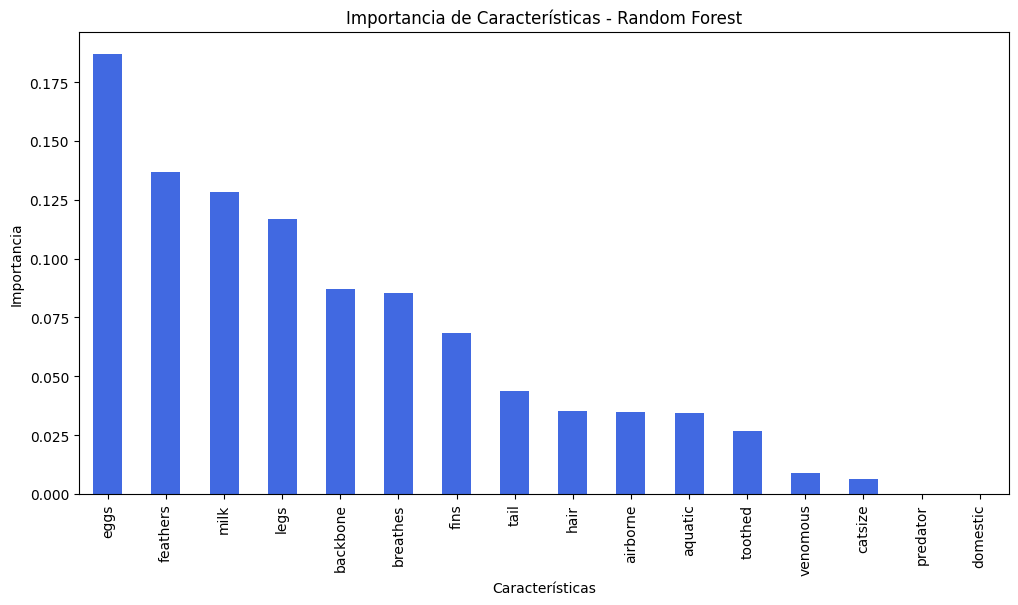

In [ ]:
# Obtener la importancia de las características
feature_importance_rf = pd.Series(random_forest.feature_importances_, index=X.columns)

# Ordenar y graficar
feature_importance_rf.sort_values(ascending=False).plot(kind='bar', figsize=(12, 6), color='royalblue')
plt.title('Importancia de Características - Random Forest')
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.show()

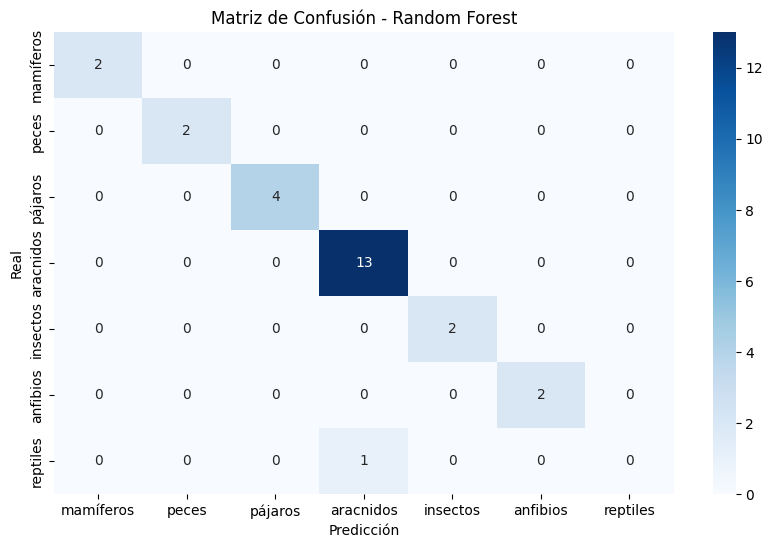

              precision    recall  f1-score   support

    anfibios       1.00      1.00      1.00         2
   aracnidos       1.00      1.00      1.00         2
    insectos       1.00      1.00      1.00         4
   mamíferos       0.93      1.00      0.96        13
       peces       1.00      1.00      1.00         2
     pájaros       1.00      1.00      1.00         2
    reptiles       0.00      0.00      0.00         1

    accuracy                           0.96        26
   macro avg       0.85      0.86      0.85        26
weighted avg       0.93      0.96      0.94        26



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Matriz de confusión
conf_matrix_rf = confusion_matrix(y_test, y_pred_forest)
plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix_rf, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
plt.title('Matriz de Confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()
print(classification_report(y_test, y_pred_forest))



# XGboost

In [ ]:
# Entrenar el modelo XGBClassifier

# Codificar las etiquetas
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Entrenar el modelo XGBClassifier
xgb_model = XGBClassifier( eval_metric='mlogloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predecir y calcular la precisión del modelo XGBoost
y_pred_xgb = xgb_model.predict(X_test)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

# Mostrar la precisión del modelo XGBoost
print(f'Precisión del modelo XGBoost: {accuracy_xgb:.2f}')

# (Opcional) Mostrar las clases originales
print("Clases originales:", label_encoder.classes_)

Precisión del modelo XGBoost: 0.95
Clases originales: ['anfibios' 'aracnidos' 'insectos' 'mamíferos' 'peces' 'pájaros'
 'reptiles']


#La importancia de cada atributo según XGBoost

<ipython-input-97-b8836ce3f01b>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance_xgb.sort_values(ascending=False), y=feature_importance_xgb.sort_values(ascending=False).index, palette="Oranges_r")


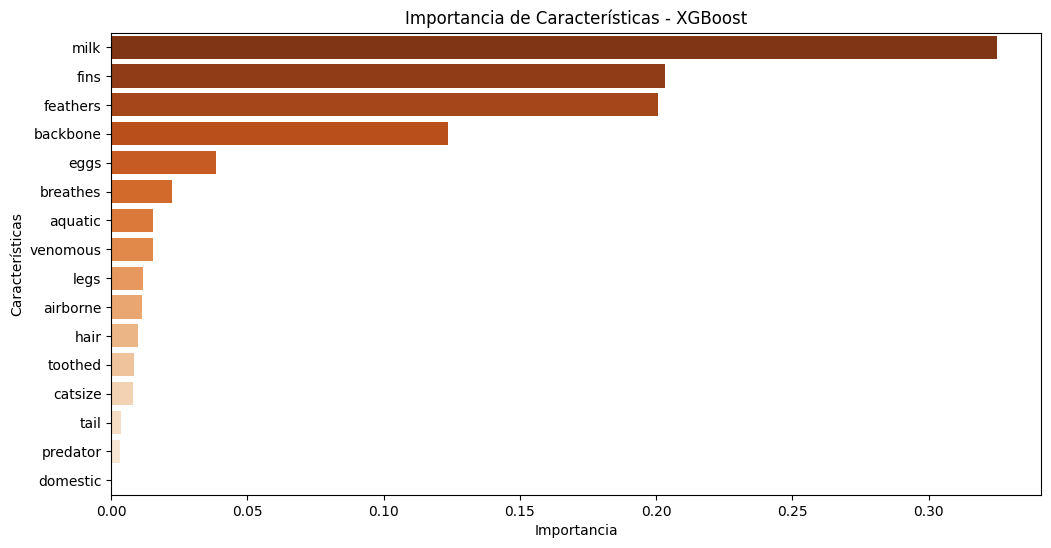

In [ ]:
# Obtener la importancia de las características
feature_importance_xgb = pd.Series(xgb_model.feature_importances_, index=X.columns)

# Graficar con Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x=feature_importance_xgb.sort_values(ascending=False), y=feature_importance_xgb.sort_values(ascending=False).index, palette="Oranges_r")
plt.title('Importancia de Características - XGBoost')
plt.xlabel('Importancia')
plt.ylabel('Características')
plt.show()

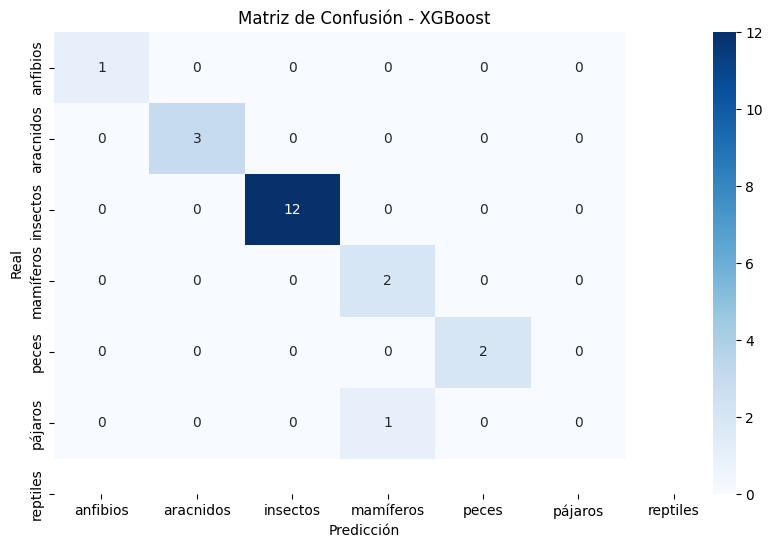

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00        12
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         2
           6       0.00      0.00      0.00         1

    accuracy                           0.95        21
   macro avg       0.78      0.83      0.80        21
weighted avg       0.92      0.95      0.93        21

Precisión del modelo XGBoost: 0.95


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Matriz de confusión
conf_matrix = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Matriz de Confusión - XGBoost')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()
print(classification_report(y_test, y_pred_xgb))
accuracy_boost = accuracy_score(y_test, y_pred_xgb)
print(f'Precisión del modelo XGBoost: {accuracy_boost:.2f}')


#Mejor Modelo
Comparando todos los modelos el que más destaca es el de árboles aleatorios. Teniendo la mejor precisión y recall.

#¿Es fácil clasificar?
Realmente si, ya que la mayoria son mamíferos, anque las categorías con menor animales sufren porque no hay realmente mucha información con qué clasificar a los animales raros.